# 03 · 进阶方法：CUPED、分群分析与多重比较、偷看问题

**本 notebook 的学习目标**
1. **CUPED**：利用实验前数据降低指标方差，让同样的样本量检测更小的效果。
2. **分群分析（Segment analysis）**：效果是否因国家而异？如何避免"分群越多越容易找到假阳性"？
3. **多重比较校正**：Bonferroni、Holm、Benjamini–Hochberg 的区别与选择。
4. **偷看问题（Peeking）**：为什么"每天看一次 p 值，显著就停"会让假阳性率暴增。

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

sys.path.insert(0, str(Path("..", "src").resolve()))
from abtest import (load_raw, clean_ab_data, two_proportion_ztest, cuped_adjust, welch_ttest,
                    bootstrap_diff_in_means, adjust_pvalues, simulate_revenue_experiment,
                    simulate_peeking)
from abtest.plotting import set_style, CONTROL, TREATMENT, ACCENT, MUTED, GROUP_COLORS

set_style()
FIG = Path("..", "reports", "figures")
pd.set_option("display.float_format", "{:,.4f}".format)

---
## Part A · CUPED 方差缩减

### 动机
第 02 节显示：在 12% 的基线下，想检测 1% 的相对提升需要每组上百万用户。大公司常用的解决办法之一是 **CUPED**（Controlled-experiment Using Pre-Experiment Data，微软 2013 年提出）。

### 思想
用户之间的差异（有人天生爱买、有人从不买）是指标方差的主要来源，但这部分差异**与实验无关**。如果我们有用户在**实验前**的同类数据 $X$，就可以把这部分"可预测的噪声"减掉：
$$Y^{cuped}_i = Y_i - \theta\,(X_i - \bar X), \qquad \theta = \frac{\operatorname{Cov}(X, Y)}{\operatorname{Var}(X)}$$

### 为什么它是无偏的？
$X$ 是实验前的数据，**不可能被实验影响**，且由于随机分组，$E[X_t] = E[X_c]$。所以
$$E[\bar Y^{cuped}_t - \bar Y^{cuped}_c] = E[\bar Y_t - \bar Y_c] - \theta\,\underbrace{E[\bar X_t - \bar X_c]}_{=0}$$
效果估计的期望不变。

### 方差减少多少？
选取上式的 $\theta$ 恰好使方差最小，此时
$$\operatorname{Var}(Y^{cuped}) = \operatorname{Var}(Y)\,(1-\rho^2), \qquad \rho = \operatorname{Corr}(X, Y)$$
相关系数 0.7 → 方差减少 49% → 等价于样本量翻倍。（数学上它和"以 $X$ 为协变量的线性回归 / ANCOVA"是一回事。）

### 关键前提
- $X$ 必须是**实验开始前**的数据（或其他不受处理影响的变量）。用实验期间的变量做协变量会引入偏差。
- $\theta$ 用**两组合并**的数据估计。
- 新用户没有历史数据时，可以把 $X$ 填 0 并加一个"是否新用户"的指示变量，或只对老用户使用。

### ⚠️ 数据说明
Udacity 公开数据集**没有**实验前数据，无法诚实地套用 CUPED。因此这里使用**模拟数据**演示：6 万名用户，指标为实验期间人均收入（右偏、大量 0），协变量为同一用户实验前同样时长的收入，**真实效果设定为 +3%**。模拟代码在 `src/abtest/simulate.py`，可以完全复现。

In [2]:
rev = simulate_revenue_experiment()   # seed=7, true_lift=0.03
rev.head()

,user_id,group,pre_revenue,revenue
0,1,control,3.9300,5.4600
1,2,control,0.0000,0.0000
2,3,treatment,0.0000,0.0000
3,4,control,2.1200,2.1700
4,5,treatment,6.8300,3.0200


In [3]:
print(rev.groupby("group")[["pre_revenue", "revenue"]].agg(["mean", "std"]))
rho = rev[["pre_revenue", "revenue"]].corr().iloc[0, 1]
print(f"\nCorr(pre, post) = {rho:.3f}  ->  理论方差缩减比例 rho^2 = {rho**2:.1%}")
print(f"零收入用户占比: {(rev.revenue == 0).mean():.1%}")

          pre_revenue         revenue        
                 mean     std    mean     std
group                                        
control        6.0898 11.3831  6.1885 11.5978
treatment      5.9575 10.7162  6.2500 11.0270

Corr(pre, post) = 0.758  ->  理论方差缩减比例 rho^2 = 57.4%
零收入用户占比: 43.8%


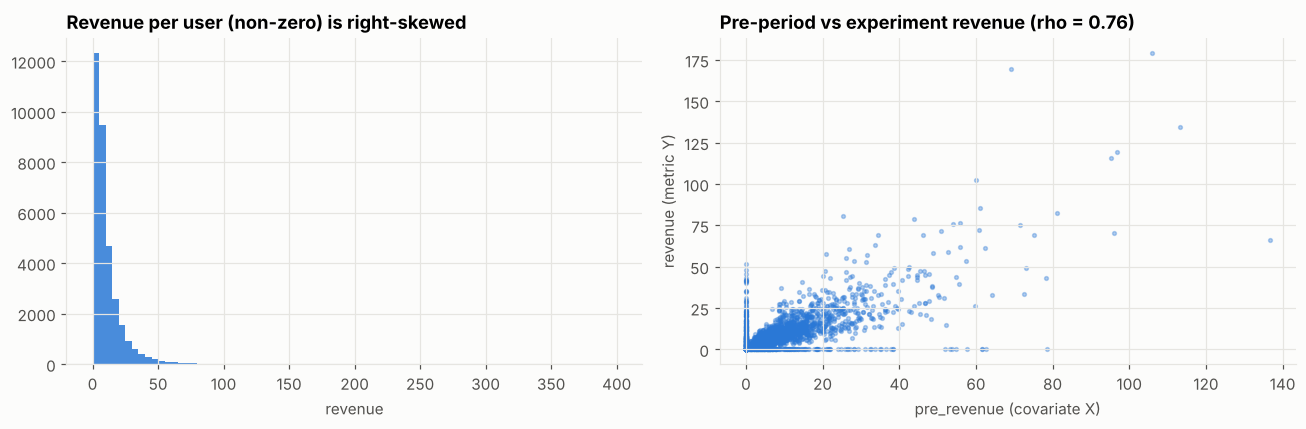

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(rev.revenue[rev.revenue > 0], bins=80, color=CONTROL, alpha=0.85)
axes[0].set_title("Revenue per user (non-zero) is right-skewed")
axes[0].set_xlabel("revenue")
sample = rev.sample(4000, random_state=0)
axes[1].scatter(sample.pre_revenue, sample.revenue, s=6, alpha=0.35, color=CONTROL)
axes[1].set_title(f"Pre-period vs experiment revenue (rho = {rho:.2f})")
axes[1].set_xlabel("pre_revenue (covariate X)")
axes[1].set_ylabel("revenue (metric Y)")
plt.tight_layout()
plt.savefig(FIG / "03_cuped_data.png")
plt.show()

### A.1 不用 CUPED：Welch t 检验
收入是连续指标，用 **Welch t 检验**（不假设两组方差相等）。虽然收入严重右偏，但样本量 3 万/组时，样本均值仍近似正态（中心极限定理）。

In [5]:
is_c = rev.group == "control"
naive = welch_ttest(rev.revenue[is_c], rev.revenue[~is_c])
print(f"差值 = {naive['diff']:.4f}, SE = {naive['se']:.4f}, p = {naive['p_value']:.4f}, "
      f"95% CI = [{naive['ci'][0]:.4f}, {naive['ci'][1]:.4f}]")

差值 = 0.0614, SE = 0.0924, p = 0.5061, 95% CI = [-0.1197, 0.2426]


### A.2 使用 CUPED

In [6]:
rev["revenue_cuped"], theta = cuped_adjust(rev.revenue, rev.pre_revenue)
cuped = welch_ttest(rev.revenue_cuped[is_c], rev.revenue_cuped[~is_c])
print(f"theta = {theta:.4f}")
print(f"差值 = {cuped['diff']:.4f}, SE = {cuped['se']:.4f}, p = {cuped['p_value']:.4f}, "
      f"95% CI = [{cuped['ci'][0]:.4f}, {cuped['ci'][1]:.4f}]")

var_red = 1 - rev.revenue_cuped.var() / rev.revenue.var()
print(f"\n方差缩减: {var_red:.1%}   SE 缩小: {1 - cuped['se']/naive['se']:.1%}")
print(f"等价样本量倍数: {1/(1-var_red):.2f}x")

true_diff = rev.revenue[is_c].mean() * 0.03
print(f"真实效果（约）: {true_diff:.4f}")

theta = 0.7755
差值 = 0.1641, SE = 0.0603, p = 0.0065, 95% CI = [0.0459, 0.2823]

方差缩减: 57.4%   SE 缩小: 34.7%
等价样本量倍数: 2.35x
真实效果（约）: 0.1857


In [7]:
# 与线性回归（ANCOVA）对比：系数几乎一样
ols = smf.ols("revenue ~ C(group) + pre_revenue", data=rev).fit(cov_type="HC1")
print(ols.summary().tables[1])

                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 1.4656      0.075     19.624      0.000       1.319       1.612
C(group)[T.treatment]     0.1641      0.060      2.730      0.006       0.046       0.282
pre_revenue               0.7755      0.014     56.340      0.000       0.749       0.803


**解读**：
- 不用 CUPED 时，差值 0.06、p = 0.51，**检测不到**真实存在的 +3% 效果。
- 观察实验前收入：这次随机分组恰好让对照组的历史收入略高（6.09 vs 5.96），"天生更爱买的人"偶然多分到了对照组，**拉低了**朴素估计。
- CUPED 做了两件事：①把 SE 缩小约 35%（方差减少约 57%，≈ $\rho^2$）；②**校正了这种偶然的组间不平衡**，估计值 0.164 更接近真实值约 0.186。最终 p ≈ 0.007，显著。
- 回归 `revenue ~ group + pre_revenue` 给出的处理效应系数与 CUPED 几乎一致 —— CUPED 本质上就是 ANCOVA。

> ⚠️ 单次模拟可能"碰巧"。下面用**重复模拟**证明 CUPED 的两个性质：无偏、且方差更小。

朴素估计 偏差均值 = +0.0060, 标准差 = 0.1673, 功效 = 21.0%
CUPED   偏差均值 = +0.0042, 标准差 = 0.1129, 功效 = 40.5%


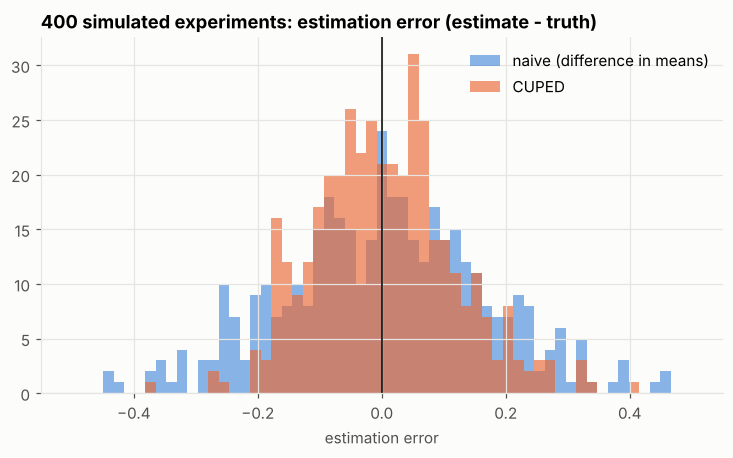

In [8]:
def one_run(seed, n=20_000):
    d = simulate_revenue_experiment(n_users=n, seed=seed)
    c = d.group == "control"
    adj, _ = cuped_adjust(d.revenue, d.pre_revenue)
    true = d.revenue[c].mean() * 0.03
    nv = welch_ttest(d.revenue[c], d.revenue[~c])
    cp = welch_ttest(adj[c], adj[~c])
    return nv["diff"] - true, cp["diff"] - true, nv["p_value"] < 0.05, cp["p_value"] < 0.05

sims = np.array([one_run(s) for s in range(400)])
print(f"朴素估计 偏差均值 = {sims[:,0].mean():+.4f}, 标准差 = {sims[:,0].std():.4f}, 功效 = {sims[:,2].mean():.1%}")
print(f"CUPED   偏差均值 = {sims[:,1].mean():+.4f}, 标准差 = {sims[:,1].std():.4f}, 功效 = {sims[:,3].mean():.1%}")

fig, ax = plt.subplots()
bins = np.linspace(-0.5, 0.5, 60)
ax.hist(sims[:, 0], bins=bins, color=CONTROL, alpha=0.55, label="naive (difference in means)")
ax.hist(sims[:, 1], bins=bins, color=TREATMENT, alpha=0.65, label="CUPED")
ax.axvline(0, color="black", lw=1)
ax.set_title("400 simulated experiments: estimation error (estimate - truth)")
ax.set_xlabel("estimation error")
ax.legend()
plt.savefig(FIG / "03_cuped_simulation.png")
plt.show()

**解读**：两种估计的误差都以 0 为中心（**都无偏**），但 CUPED 的分布窄得多（**方差更小**），因此在同样样本量下**功效更高**。这就是 CUPED 的全部价值：不改变"打靶的中心"，只让"弹着点更集中"。

### A.3 Bootstrap 用在偏态的连续指标上
第 02 节提到 Bootstrap 在偏态指标上更有价值。这里对原始收入做一次 Bootstrap 作为对 t 检验的稳健性检查。

In [9]:
b = bootstrap_diff_in_means(rev.revenue_cuped[is_c].values, rev.revenue_cuped[~is_c].values,
                            n_boot=2000)
print(f"CUPED 指标 Bootstrap 95% CI: [{b['ci'][0]:.4f}, {b['ci'][1]:.4f}]  vs  t 检验: "
      f"[{cuped['ci'][0]:.4f}, {cuped['ci'][1]:.4f}]")

CUPED 指标 Bootstrap 95% CI: [0.0449, 0.2790]  vs  t 检验: [0.0459, 0.2823]


---
## Part B · 分群分析与多重比较校正（回到真实数据）

整体不显著时，业务方常问："那**某个国家**是不是有效果？" 这是合理的问题（效果异质性，heterogeneous treatment effect），但也是**最容易产生假阳性**的地方。

In [10]:
df = clean_ab_data(*load_raw(), verbose=False)

rows = []
for country, d in df.groupby("country"):
    g = d.groupby("group").converted.agg(["sum", "count"])
    r = two_proportion_ztest(*g.loc["control"], *g.loc["treatment"])
    rows.append({"country": country, "n": len(d), "p_control": r.p_control,
                 "p_treatment": r.p_treatment, "abs_diff": r.abs_diff,
                 "ci_low": r.ci_abs[0], "ci_high": r.ci_abs[1], "p_value": r.p_value})
seg = pd.DataFrame(rows).set_index("country")
seg

,n,p_control,p_treatment,abs_diff,ci_low,ci_high,p_value
country,,,,,,,
CA,14499,0.1188,0.1119,-0.0069,-0.0173,0.0035,0.1947
UK,72466,0.1200,0.1212,0.0011,-0.0036,0.0059,0.6349
US,203619,0.1206,0.1185,-0.0022,-0.0050,0.0007,0.1323


### B.1 多重比较问题
每做一次 α = 0.05 的检验，就有 5% 的假阳性概率。做 $m$ 次**独立**检验，至少一次假阳性的概率（族错误率，FWER）为
$$\text{FWER} = 1 - (1-\alpha)^m$$
$m = 3$ 时 ≈ 14%；$m = 20$ 时 ≈ 64%。如果切 20 个分群总能"发现"一个显著的，那几乎一定是噪声。

### B.2 三种校正方法

| 方法 | 控制什么 | 做法 | 特点 |
|---|---|---|---|
| **Bonferroni** | FWER | $p_{adj} = \min(m\,p, 1)$ | 最简单、最保守 |
| **Holm**（逐步降低） | FWER | p 值从小到大排序，第 $k$ 个乘以 $(m-k+1)$，并保证单调 | **总是不劣于** Bonferroni，推荐替代 |
| **Benjamini–Hochberg** | FDR（错误发现率） | 第 $k$ 个乘以 $m/k$，并保证单调 | 功效更高，适合探索性的大量检验 |

- **FWER**：所有显著结果中**至少有一个**是假的的概率。适合"一旦错就有严重后果"的确认性结论。
- **FDR**：所有显著结果中，**假的所占比例**的期望。适合大规模探索（例如筛选 100 个指标）后再做验证。

In [11]:
for m in ["bonferroni", "holm", "bh"]:
    seg[f"p_{m}"] = adjust_pvalues(seg.p_value.values, m)
seg[["abs_diff", "p_value", "p_bonferroni", "p_holm", "p_bh"]]

,abs_diff,p_value,p_bonferroni,p_holm,p_bh
country,,,,,
CA,-0.0069,0.1947,0.5840,0.3968,0.2920
UK,0.0011,0.6349,1.0000,0.6349,0.6349
US,-0.0022,0.1323,0.3968,0.3968,0.2920


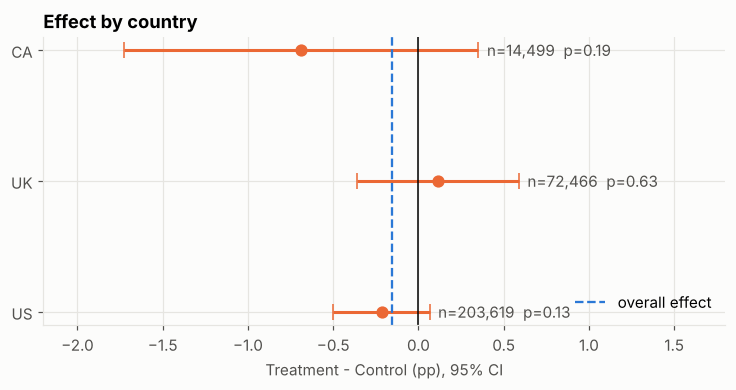

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.4))
order = ["US", "UK", "CA"]
for i, c in enumerate(order):
    r = seg.loc[c]
    ax.errorbar(r.abs_diff * 100, i, xerr=[[(r.abs_diff - r.ci_low) * 100], [(r.ci_high - r.abs_diff) * 100]],
                fmt="o", color=TREATMENT, capsize=5, ms=7)
    ax.text(r.ci_high * 100 + 0.05, i, f"n={int(r.n):,}  p={r.p_value:.2f}", va="center", color=MUTED)
overall = two_proportion_ztest(*df.groupby("group").converted.agg(["sum", "count"]).values.ravel())
ax.axvline(overall.abs_diff * 100, color=CONTROL, ls="--", lw=1.5, label="overall effect")
ax.axvline(0, color="black", lw=1)
ax.set_yticks(range(len(order)), order)
ax.set_xlim(-2.2, 1.8)
ax.set_xlabel("Treatment - Control (pp), 95% CI")
ax.set_title("Effect by country")
ax.legend(loc="lower right")
plt.savefig(FIG / "03_segment_effects.png")
plt.show()

**解读**：三个国家没有一个显著（未校正 p 已经都 > 0.05，校正后更不显著）。加拿大的点估计最负但样本只有 1.4 万，区间很宽。

### B.3 更正确的问法：交互作用检验
"各国效果是否**不同**？"不应该通过"美国显著、英国不显著"来判断（显著与不显著之间的差异本身未必显著）。正确的做法是用逻辑回归直接检验 **组别 × 国家** 的交互项：
$$\operatorname{logit} P(\text{converted}) = \beta_0 + \beta_1\,\text{treatment} + \gamma\,\text{country} + \delta\,(\text{treatment} \times \text{country})$$
用**似然比检验**比较有/无交互项的两个模型：$H_0$：所有 $\delta = 0$（效果在各国相同）。

In [13]:
m0 = smf.logit("converted ~ treatment + C(country)", data=df).fit(disp=False)
m1 = smf.logit("converted ~ treatment * C(country)", data=df).fit(disp=False)
lr = 2 * (m1.llf - m0.llf)
dof = m1.df_model - m0.df_model
print(m1.summary().tables[1])
print(f"\n似然比检验: LR = {lr:.3f}, dof = {int(dof)}, p = {stats.chi2.sf(lr, dof):.4f}")

                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept                     -2.0040      0.036    -55.008      0.000      -2.075      -1.933
C(country)[T.UK]               0.0118      0.040      0.296      0.767      -0.066       0.090
C(country)[T.US]               0.0175      0.038      0.465      0.642      -0.056       0.091
treatment                     -0.0674      0.052     -1.297      0.195      -0.169       0.034
treatment:C(country)[T.UK]     0.0783      0.057      1.378      0.168      -0.033       0.190
treatment:C(country)[T.US]     0.0469      0.054      0.872      0.383      -0.059       0.152

似然比检验: LR = 2.465, dof = 2, p = 0.2916


**解读**：交互项的似然比检验 p > 0.05，**没有证据表明新页面的效果因国家而异**。注意：有交互项时，`treatment` 系数表示**基准类别（加拿大）**里的效果，不是整体效果；它同样不显著。

> 💡 **面试要点**：分群分析应当**事先声明**要看哪些分群（pre-registration），事后发现的分群效应只能当作"假设"，需要新实验验证。否则就是 HARKing（Hypothesizing After the Results are Known）。
>
> 另外要警惕**辛普森悖论**：各分群方向与整体方向相反的情况，通常由分群间样本占比在两组中不同引起。本实验两组国家占比一致（见 01），因此不存在这个问题。

---
## Part C · 偷看问题（Peeking）

### 问题
业务方很常见的做法：每天看一次 p 值，一旦 < 0.05 就宣布胜利、停止实验。这会让假阳性率远超 5%。原因：p 值在 $H_0$ 下会随样本累积**随机游走**，看的次数越多，越有机会某一次"碰巧"跌破 0.05。

### 模拟
跑 2,000 个 **A/A 实验**（两组完全相同，任何"显著"都是假阳性），每个实验分 20 批进入用户，每批后看一次 p 值。

只在最后看一次的假阳性率:     4.5%
每批都看、显著就停的假阳性率: 23.4%


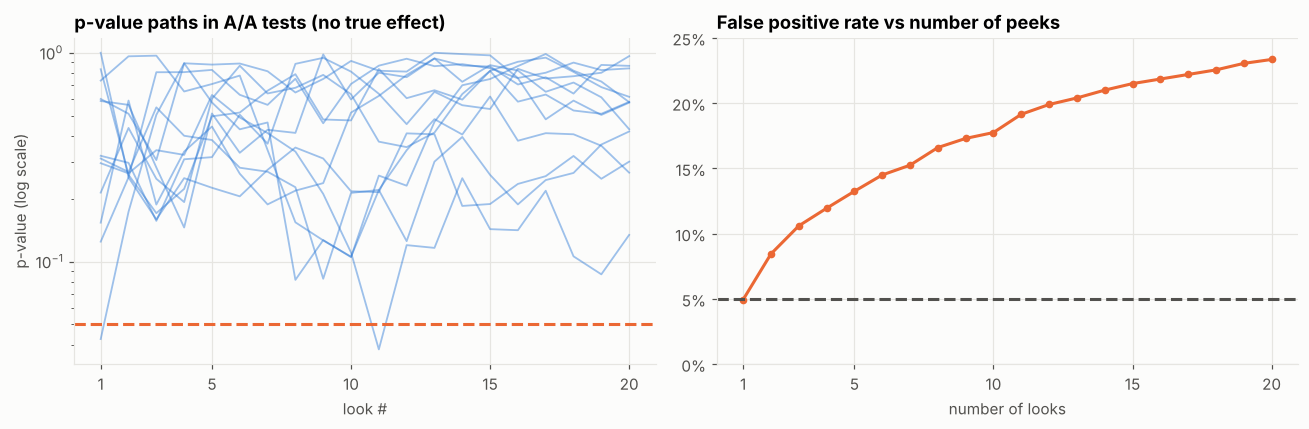

In [14]:
pk = simulate_peeking(n_experiments=2000, n_per_look=1000, n_looks=20)
print(f"只在最后看一次的假阳性率:     {pk['fpr_final_look']:.1%}")
print(f"每批都看、显著就停的假阳性率: {pk['fpr_any_look']:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for path in pk["pvalue_paths"][:12]:
    axes[0].plot(np.arange(1, 21), path, color=CONTROL, alpha=0.45, lw=1.2)
axes[0].axhline(0.05, color=TREATMENT, ls="--")
axes[0].set_yscale("log")
axes[0].set_title("p-value paths in A/A tests (no true effect)")
axes[0].set_xlabel("look #")
axes[0].set_ylabel("p-value (log scale)")
axes[1].plot(np.arange(1, 21), pk["fpr_by_n_looks"], color=TREATMENT, marker="o", ms=4)
axes[1].axhline(0.05, color=MUTED, ls="--")
axes[1].set_yticks(np.arange(0, 0.30, 0.05))
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
for ax in axes:
    ax.set_xticks([1, 5, 10, 15, 20])
axes[1].set_title("False positive rate vs number of peeks")
axes[1].set_xlabel("number of looks")
plt.tight_layout()
plt.savefig(FIG / "03_peeking.png")
plt.show()

**解读**：只看一次时假阳性率 ≈ 5%（符合设计），但偷看 20 次后上升到 **20% 以上**。

**解决办法**：
1. **固定样本量**：事先用功效分析定好样本量，期间可以看数据做"健康检查"（SRM、bug），但不做停止决策。
2. **序贯检验（Sequential testing）**：如 O'Brien–Fleming 型 α 消耗函数（group sequential），或 mSPRT / always-valid p 值，允许中途查看并正确控制假阳性率。
3. **贝叶斯方法**：报告"新版更好的后验概率"，但它同样需要预先定义停止规则，并不能免除偷看问题。

本项目的真实实验跑满了约 3 周、在最后做一次分析，不存在偷看问题。

---
## 总结

| 方法 | 解决什么问题 | 本项目结论 |
|---|---|---|
| CUPED | 方差大、需要样本多 | 模拟中方差 ↓57%，相当于样本量 ×2.3；在真实项目中需要实验前数据 |
| 分群 + 多重比较校正 | 分群越多假阳性越多 | 各国均不显著，Holm / BH 校正后仍不显著 |
| 交互作用检验 | 判断效果是否因群体而异 | 似然比检验不显著 → 效果在各国一致 |
| 偷看模拟 | 中途多次查看导致假阳性 | 20 次偷看让假阳性率从 5% 升到 20%+ |

**最终业务结论不变：不上线新页面。**

### 🧠 自测题
1. 为什么 CUPED 的协变量不能用实验期间的浏览次数？（答：浏览次数可能被新页面影响，调整后会把一部分真实效果减掉，引入偏差。）
2. 有 10 个分群，最小 p 值是 0.008，Bonferroni 校正后还显著吗？（答：0.008 × 10 = 0.08 > 0.05，不显著。）
3. Holm 为什么比 Bonferroni 好？（答：同样控制 FWER，但除最小的 p 值外乘的系数更小，功效更高，没有任何代价。）